In [1]:
import numpy as np
import pandas as pd

!pip install requests


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import requests

In [3]:
# importing the countries.
url = "https://api.worldbank.org/countries?format=json&per_page=300"

response = requests.get(url)
response.status_code

200

In [4]:
data = response.json()
print(data[0])
print(len(data))

# 1- metadata
# 2 -Actual data

{'page': 1, 'pages': 1, 'per_page': '300', 'total': 296}
2


In [5]:
countries= data[1]
countries= pd.DataFrame(countries)

In [6]:
countries["incomeLevel"][6]

{'id': 'UMC', 'iso2code': 'XT', 'value': 'Upper middle income'}

In [7]:
countries["region"]= countries["region"].apply(lambda x:x["value"])

In [8]:
countries["incomeLevel"]= countries["incomeLevel"].apply(lambda x:x["value"])

In [9]:
countries["lendingType"]= countries["lendingType"].apply(lambda x:x["value"])

In [10]:
countries.drop(columns=["adminregion","adminregion"], inplace=True)

In [11]:
countries.drop(columns=["capitalCity"], inplace=True)

In [12]:
countries["region"].unique()

<ArrowStringArray>
[                       'Latin America & Caribbean ',
                                        'Aggregates',
 'Middle East, North Africa, Afghanistan & Pakistan',
                               'Sub-Saharan Africa ',
                             'Europe & Central Asia',
                               'East Asia & Pacific',
                                        'South Asia',
                                     'North America']
Length: 8, dtype: str

In [13]:
countries.rename(columns={"iso2Code":"country_id"}, inplace=True)

In [14]:
countries[countries["region"]=="Aggregates"]

,id,country_id,name,region,incomeLevel,lendingType,longitude,latitude
1,AFE,ZH,Africa Eastern and Southern,Aggregates,Aggregates,Aggregates,,
3,AFR,A9,Africa,Aggregates,Aggregates,Aggregates,,
4,AFW,ZI,Africa Western and Central,Aggregates,Aggregates,Aggregates,,
8,ARB,1A,Arab World,Aggregates,Aggregates,Aggregates,,
18,BEA,B4,East Asia & Pacific (IBRD-only countries),Aggregates,Aggregates,Aggregates,,
...,...,...,...,...,...,...,...,...
269,TSA,T5,South Asia (IDA & IBRD),Aggregates,Aggregates,Aggregates,,
270,TSS,T6,Sub-Saharan Africa (IDA & IBRD countries),Aggregates,Aggregates,Aggregates,,
278,UMC,XT,Upper middle income,Aggregates,Aggregates,Aggregates,,
288,WLD,1W,World,Aggregates,Aggregates,Aggregates,,


In [15]:
# code for indicators
base_url="https://api.worldbank.org/v2/indicators?format=json"
response= requests.get(base_url)
response.status_code

200

In [16]:
indicators_data = response.json()

In [17]:
indicators_data[0]

{'page': 1, 'pages': 591, 'per_page': '50', 'total': 29544}

In [18]:
indicators_data[1]

[{'id': '1.0.HCount.1.90usd',
  'name': 'Poverty Headcount ($1.90 a day)',
  'unit': '',
  'source': {'id': '37', 'value': 'LAC Equity Lab'},
  'sourceNote': 'The poverty headcount index measures the proportion of the population with daily per capita income (in 2011 PPP) below the poverty line.',
  'sourceOrganization': 'LAC Equity Lab tabulations of SEDLAC (CEDLAS and the World Bank).',
  'topics': [{'id': '11', 'value': 'Poverty '}]},
 {'id': '1.0.HCount.2.5usd',
  'name': 'Poverty Headcount ($2.50 a day)',
  'unit': '',
  'source': {'id': '37', 'value': 'LAC Equity Lab'},
  'sourceNote': 'The poverty headcount index measures the proportion of the population with daily per capita income (in 2005 PPP) below the poverty line.',
  'sourceOrganization': 'LAC Equity Lab tabulations of SEDLAC (CEDLAS and the World Bank).',
  'topics': [{'id': '11', 'value': 'Poverty '}]},
 {'id': '1.0.HCount.Mid10to50',
  'name': 'Middle Class ($10-50 a day) Headcount',
  'unit': '',
  'source': {'id': '37

In [19]:
all_dfs = []
page, pages = 1, 1
while page <= pages:
    r = requests.get(f"https://api.worldbank.org/v2/indicators?format=json&per_page=500&page={page}", timeout=60)
    if r.status_code != 200:
        print(f"Failed page {page}: {r.status_code}"); break
    data = r.json()
    pages = data[0]["pages"]
    all_dfs.append(pd.DataFrame([{"id": i["id"], "name": i["name"]} for i in data[1]]))
    page += 1

In [20]:
final_df= pd.concat(all_dfs, ignore_index=True)

In [21]:
final_df.to_csv("final_df.csv")

In [22]:
# extacry value for various indicators under the domain for each country

In [23]:
indicator_groups = {
"economic_activity_growth": [
"NY.GDP.MKTP.KD.ZG", # GDP growth (annual %)
"NY.GDP.PCAP.CD" # GDP per capita (current US$)
],
"labour_market_indicators": [
"SL.UEM.TOTL.ZS", # Unemployment total
"SL.UEM.1524.ZS", # Unemployment youth total (ages 15–24)
"SL.TLF.TOTL.IN" # Labour force, total
],
"trade_globalization": [
"NE.EXP.GNFS.CD", # Exports of goods and services (current US$)
"NE.IMP.GNFS.CD" # Imports of goods and services (current US$)
],
"poverty_inequality": [
"SI.POV.NAHC", # Poverty headcount ratio at national poverty lines (% of population)
"SI.POV.GINI" # Gini index (measure of income inequality)
],
"environmental_indicators": [
"EG.FEC.RNEW.ZS", # Renewable energy consumption (% of total final energy consumption)
"AG.LND.FRST.ZS" # Forest area (% of land area)
],
"health_indicators": [
"SP.DYN.LE00.IN", # Life expectancy at birth
"SP.DYN.IMRT.IN", # Infant mortality rate
"SH.H2O.BASW.ZS", # Access to at least basic water services (% of population)
"SH.XPD.CHEX.GD.ZS", # Current health expenditure (% of GDP)
"SH.IMM.IDPT", # Immunization, DPT (% of children ages 12–23 months)
"SH.IMM.MEAS", # Immunization, measles (% of children ages 12–23 months)
"SH.MMR.RISK.ZS", # Risk of maternal death
"SH.DTH.COMM.ZS", # Deaths from communicable diseases (% of total)
"SH.TBS.INCD", # Tuberculosis incidence (per 100,000 people)
"SH.STA.BRTC.ZS", # Births attended by skilled health staff (%)
"SH.STA.MMRT", # Maternal mortality ratio (modeled estimate, per 100,000 live births)
"SP.POP.65UP.TO.ZS", # Population ages 65 and above (% of total population)
"SH.HIV.INCD.ZS" # HIV incidence rate (per 1,000 uninfected population ages 15–49)
],
"technology_indicators": [
"IT.NET.USER.ZS", # Individuals using the Internet (% of population)
"IT.CEL.SETS.P2" # Mobile cellular subscriptions (per 100 people)
]}

In [24]:
for i,j in indicator_groups.items():
  print(j)

['NY.GDP.MKTP.KD.ZG', 'NY.GDP.PCAP.CD']
['SL.UEM.TOTL.ZS', 'SL.UEM.1524.ZS', 'SL.TLF.TOTL.IN']
['NE.EXP.GNFS.CD', 'NE.IMP.GNFS.CD']
['SI.POV.NAHC', 'SI.POV.GINI']
['EG.FEC.RNEW.ZS', 'AG.LND.FRST.ZS']
['SP.DYN.LE00.IN', 'SP.DYN.IMRT.IN', 'SH.H2O.BASW.ZS', 'SH.XPD.CHEX.GD.ZS', 'SH.IMM.IDPT', 'SH.IMM.MEAS', 'SH.MMR.RISK.ZS', 'SH.DTH.COMM.ZS', 'SH.TBS.INCD', 'SH.STA.BRTC.ZS', 'SH.STA.MMRT', 'SP.POP.65UP.TO.ZS', 'SH.HIV.INCD.ZS']
['IT.NET.USER.ZS', 'IT.CEL.SETS.P2']


In [25]:
import time
import requests
import pandas as pd

base_url = ("https://api.worldbank.org/v2/country/all/indicator/{}"
            "?format=json&per_page=1000&page={}&date=2016:2025")

def fetch_page(url, retries=4):
    for attempt in range(retries):
        try:
            r = requests.get(url, timeout=60)
            if r.status_code == 200:
                return r.json()
            print(f"  status {r.status_code}, retry {attempt+1}")
        except requests.exceptions.RequestException as e:
            print(f"  {type(e).__name__}, retry {attempt+1}")
        time.sleep(2 ** attempt)
    return None

category_dataframes = {}

for category, indicators in indicator_groups.items():
    print(f"Category: {category}")
    frames = []

    for code in indicators:
        print(f"  Indicator: {code}")
        page, total_pages = 1, 1
        while page <= total_pages:
            data = fetch_page(base_url.format(code, page))
            if data is None or len(data) < 2 or data[1] is None:
                print(f"  No data / failed for {code} page {page}")
                break

            total_pages = data[0]["pages"]
            df = pd.json_normalize(data[1])[[
                "country.id", "country.value", "indicator.id",
                "indicator.value", "date", "value"
            ]].rename(columns={
                "country.id": "country_id",
                "country.value": "country_value",
                "indicator.id": "indicator_id",
                "indicator.value": "indicator_name",
                "date": "year",
            })
            df["year"] = df["year"].astype(int)
            frames.append(df)
            page += 1
            time.sleep(0.3)

    if frames:
        out = pd.concat(frames, ignore_index=True).dropna(subset=["value"])
        category_dataframes[category] = out
        out.to_csv(f"{category}.csv", index=False)   # saved so a crash doesn't lose progress
        print(f"  Rows: {len(out)}")

print("Data fetching completed!")

Category: economic_activity_growth
  Indicator: NY.GDP.MKTP.KD.ZG
  Indicator: NY.GDP.PCAP.CD
  Rows: 5083
Category: labour_market_indicators
  Indicator: SL.UEM.TOTL.ZS
  Indicator: SL.UEM.1524.ZS
  Indicator: SL.TLF.TOTL.IN
  Rows: 7008
Category: trade_globalization
  Indicator: NE.EXP.GNFS.CD
  Indicator: NE.IMP.GNFS.CD
  Rows: 4437
Category: poverty_inequality
  Indicator: SI.POV.NAHC
  Indicator: SI.POV.GINI
  Rows: 1150
Category: environmental_indicators
  Indicator: EG.FEC.RNEW.ZS
  Indicator: AG.LND.FRST.ZS
  Rows: 3886
Category: health_indicators
  Indicator: SP.DYN.LE00.IN
  Indicator: SP.DYN.IMRT.IN
  Indicator: SH.H2O.BASW.ZS
  Indicator: SH.XPD.CHEX.GD.ZS
  Indicator: SH.IMM.IDPT
  Indicator: SH.IMM.MEAS
  Indicator: SH.MMR.RISK.ZS
  Indicator: SH.DTH.COMM.ZS
  Indicator: SH.TBS.INCD
  Indicator: SH.STA.BRTC.ZS
  Indicator: SH.STA.MMRT
  Indicator: SP.POP.65UP.TO.ZS
  Indicator: SH.HIV.INCD.ZS
  Rows: 24433
Category: technology_indicators
  Indicator: IT.NET.USER.ZS
  Indi

In [26]:
economic_activity= category_dataframes.get("economic_activity_growth", pd.DataFrame())
labour_market_jobs= category_dataframes.get("labour_market_indicators", pd.DataFrame())
trade_globalization= category_dataframes.get("trade_globalization", pd.DataFrame())
poverty_inequality= category_dataframes.get("poverty_inequality", pd.DataFrame())
environmental_indicators= category_dataframes.get("environmental_indicators", pd.DataFrame())
health_indicators= category_dataframes.get("health_indicators", pd.DataFrame())
technology_indicators= category_dataframes.get("technology_indicators", pd.DataFrame())

In [27]:
economic= pd.merge(economic_activity, countries, on ="country_id", how="inner")
labour_market = pd.merge(labour_market_jobs, countries, on ="country_id", how="inner")
trade= pd.merge(trade_globalization, countries, on ="country_id", how="inner")
poverty= pd.merge(poverty_inequality, countries, on ="country_id", how="inner")
environment= pd.merge(environmental_indicators, countries, on ="country_id", how="inner")
health=pd.merge(health_indicators, countries, on ="country_id", how="inner")
technology=pd.merge(technology_indicators, countries, on ="country_id", how="inner")

In [28]:
economic.drop(columns=["indicator_id","name","id"], inplace=True)
trade.drop(columns=["indicator_id","name","id"], inplace=True)
labour_market.drop(columns=["indicator_id","name","id"], inplace=True)
poverty.drop(columns=["indicator_id","name","id"], inplace=True)
environment.drop(columns=["indicator_id","name","id"], inplace=True)
health.drop(columns=["indicator_id","name","id"], inplace=True)
technology.drop(columns=["indicator_id","name","id"], inplace=True)

In [29]:
health

,country_id,country_value,indicator_name,year,value,region,incomeLevel,lendingType,longitude,latitude
0,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2024,65.349930,Aggregates,Aggregates,Aggregates,,
1,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2023,65.146228,Aggregates,Aggregates,Aggregates,,
2,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2022,64.487152,Aggregates,Aggregates,Aggregates,,
3,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2021,62.979999,Aggregates,Aggregates,Aggregates,,
4,ZH,Africa Eastern and Southern,"Life expectancy at birth, total (years)",2020,63.766484,Aggregates,Aggregates,Aggregates,,
...,...,...,...,...,...,...,...,...,...,...
24428,ZW,Zimbabwe,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",2020,1.900000,Sub-Saharan Africa,Lower middle income,Blend,31.0672,-17.8312
24429,ZW,Zimbabwe,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",2019,2.300000,Sub-Saharan Africa,Lower middle income,Blend,31.0672,-17.8312
24430,ZW,Zimbabwe,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",2018,2.700000,Sub-Saharan Africa,Lower middle income,Blend,31.0672,-17.8312
24431,ZW,Zimbabwe,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",2017,3.600000,Sub-Saharan Africa,Lower middle income,Blend,31.0672,-17.8312


In [30]:
df_wide = health.pivot_table(index=["country_value","year"],
                             columns="indicator_name",
                             values="value"
                             )

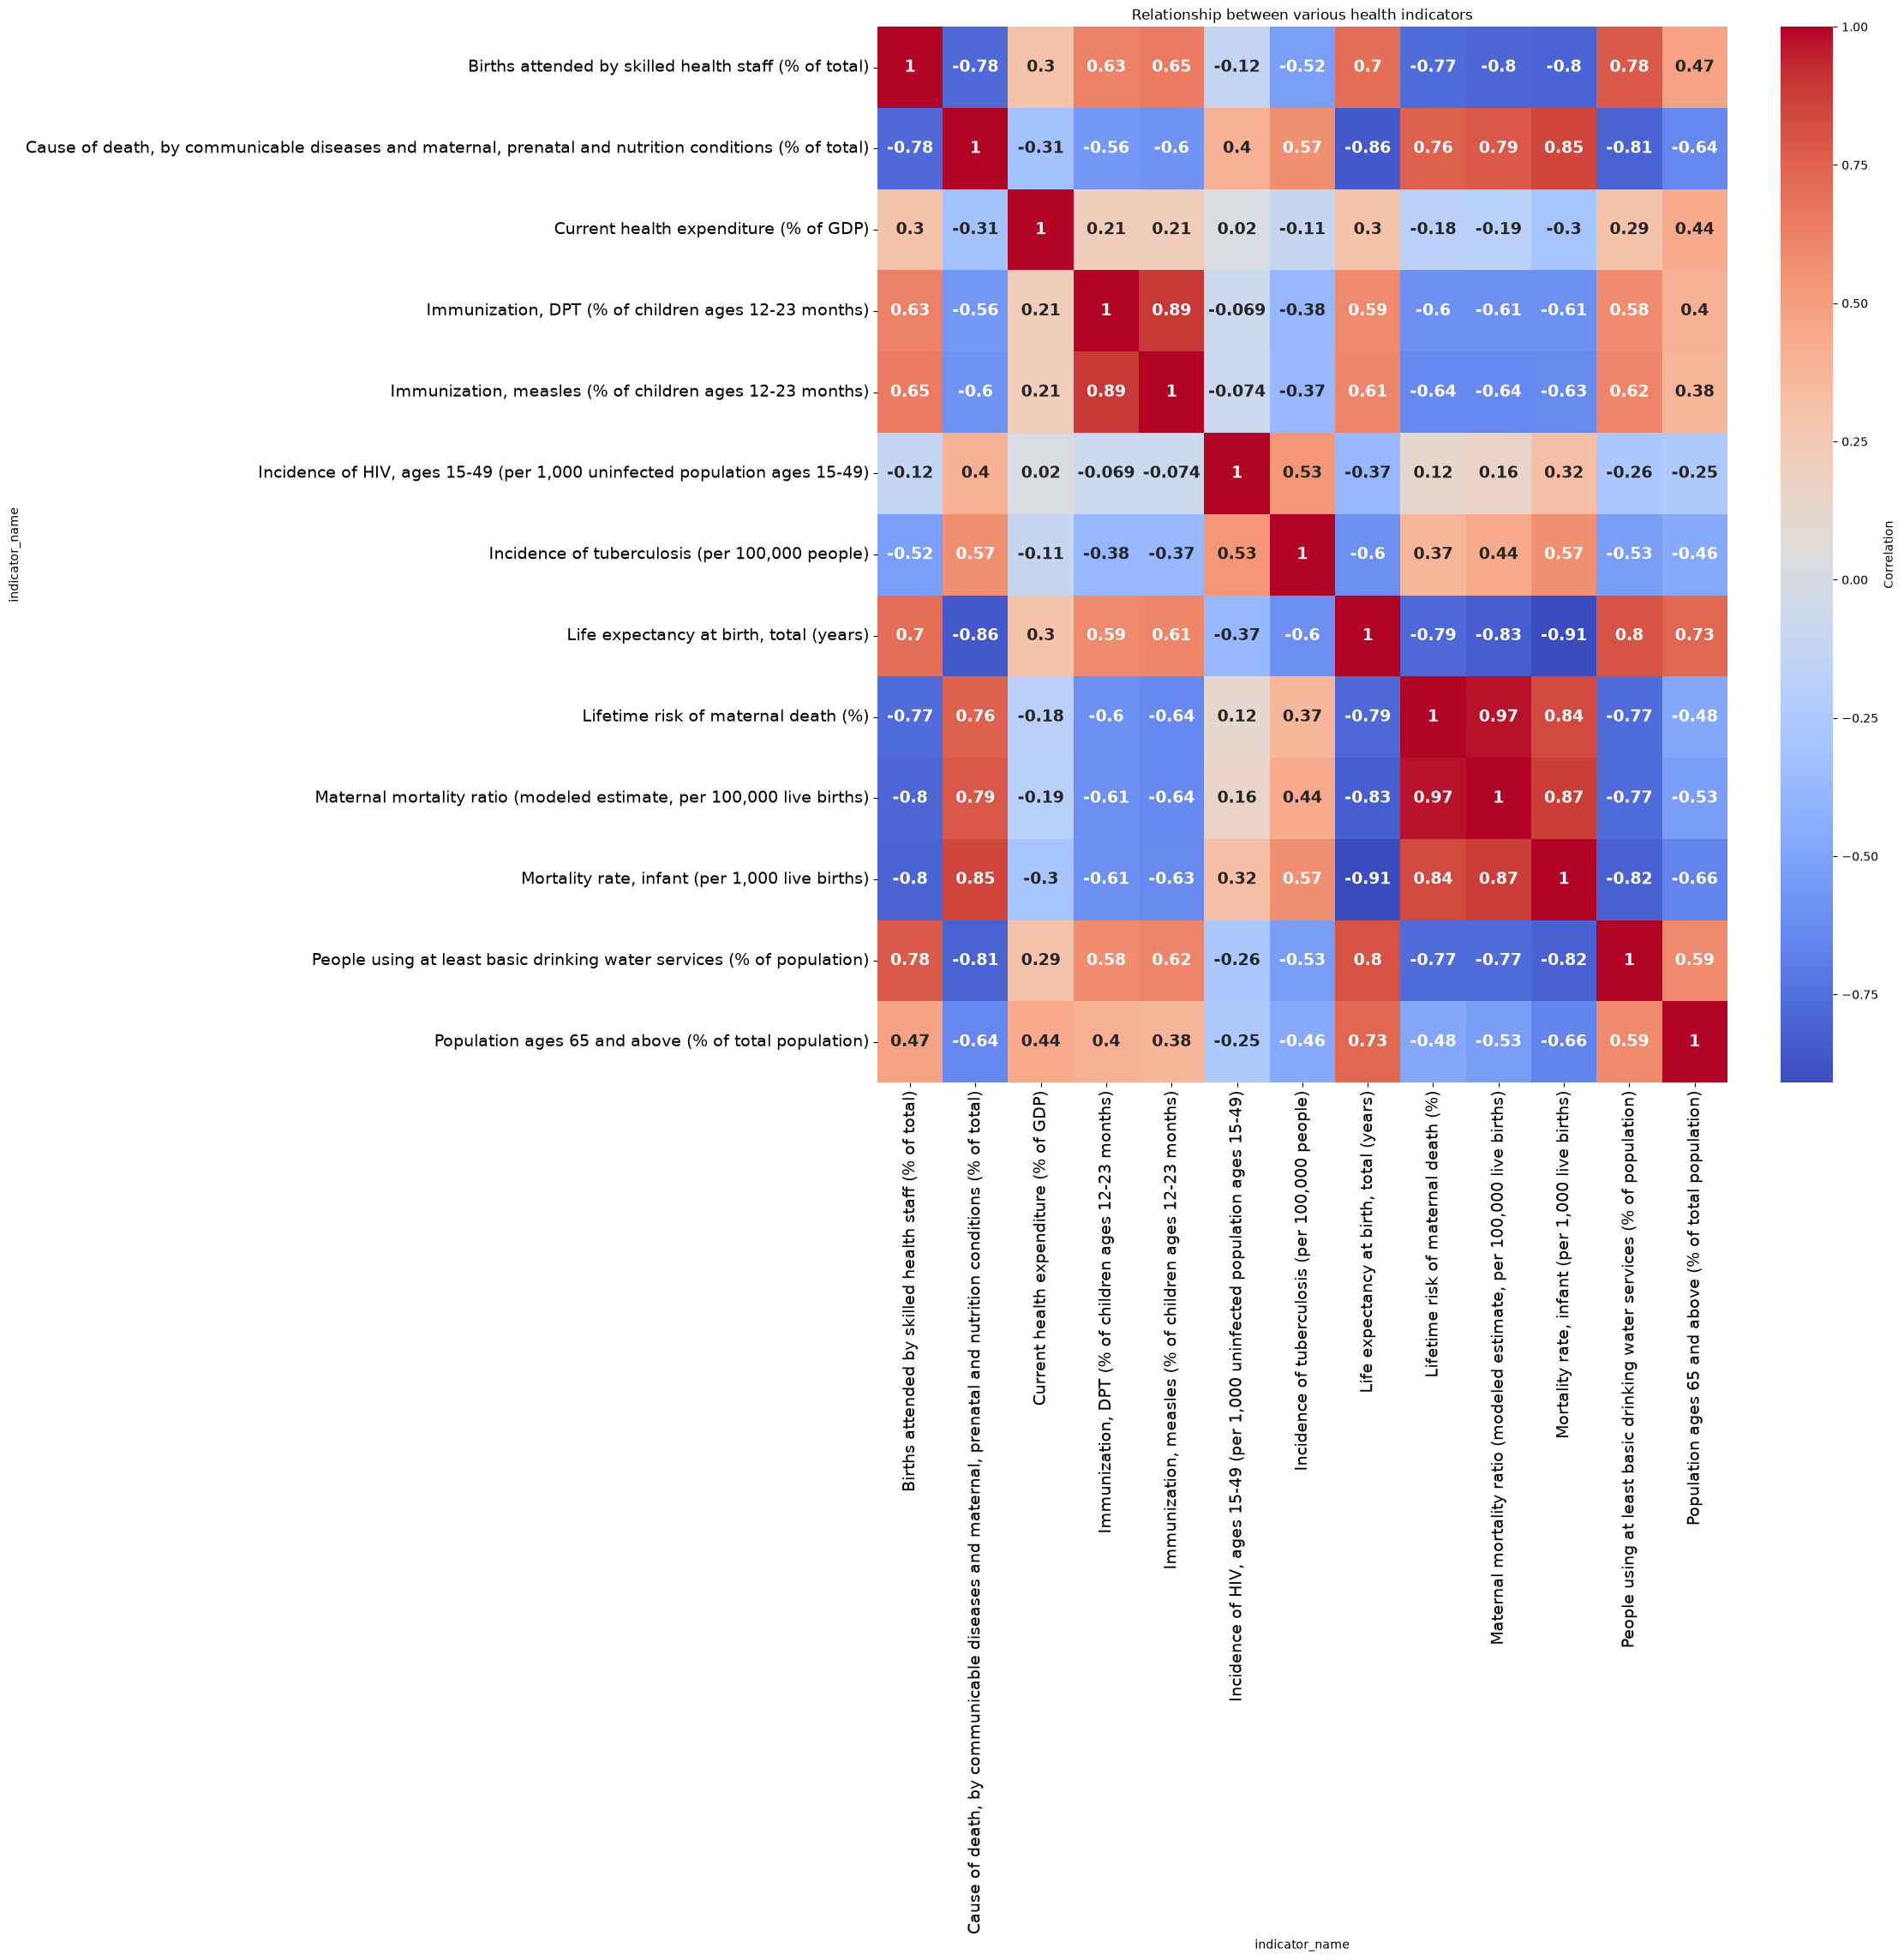

In [31]:
df_wide = health.pivot_table(index=["country_value","year"],
                             columns="indicator_name",
                             values="value"
                             )
corr= df_wide.corr()
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16,16), facecolor="none")
ax= sns.heatmap(
    corr,
    annot=True,
    cmap= "coolwarm",
    cbar_kws= {"label":"Correlation"},
    annot_kws= {"fontsize":14, "fontweight":"bold"}
)
plt.title("Relationship between various health indicators")

ax.tick_params(axis="x",labelsize=14)
ax.tick_params(axis="y",labelsize=14)
plt.show()

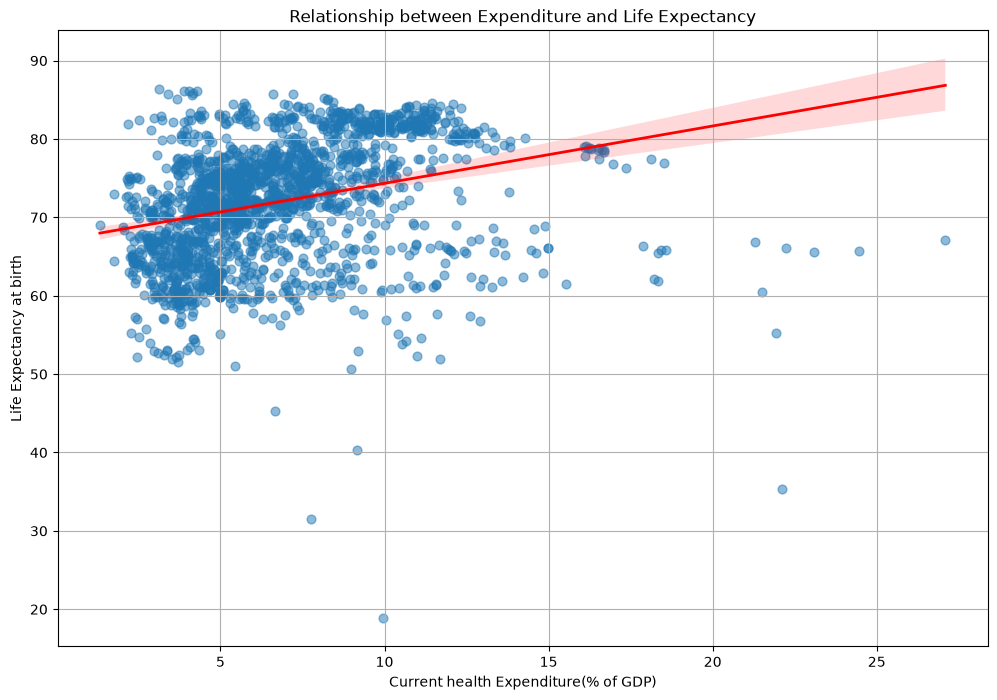

In [32]:
df_pivot= health.pivot(index=["country_value", "year"], columns="indicator_name", values="value").reset_index()

plt.figure(figsize=(12,8), facecolor="none")

ax=sns.regplot(data=df_pivot,
               x="Current health expenditure (% of GDP)",
               y="Life expectancy at birth, total (years)",
               scatter_kws= {"alpha":0.5, "s":40},
               line_kws={"color":"red","lw":2}
               )

plt.title("Relationship between Expenditure and Life Expectancy")
plt.xlabel("Current health Expenditure(% of GDP)")
plt.ylabel("Life Expectancy at birth")
plt.grid(True)
plt.show()